Shape: (1000, 10)
        Item_Name                                            details  \
0            Dior  Christian Dior Sauvage Men's EDP 3.4 oz Fragra...   
1         AS SHOW  A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...   
2       Unbranded                   HOGO BOSS cologne For Men 3.4 oz   
3  Giorgio Armani  Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...   
4         Lattafa  Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...   

          Catatory   price priceWithCurrency  available  \
0    Eau de Parfum   84.99      US $84.99/ea       10.0   
1    Eau de Parfum     NaN        US $109.99        8.0   
2  Eau de Toilette  100.00        US $100.00       10.0   
3  Eau de Toilette     NaN      US $44.99/ea        2.0   
4       Fragrances   16.91               NaN        NaN   

                                    text   sold                lastUpdated  \
0      More than 10 available / 116 sold    NaN  May 24, 2024 10:03:04 PDT   
1                  8 available / 48 so

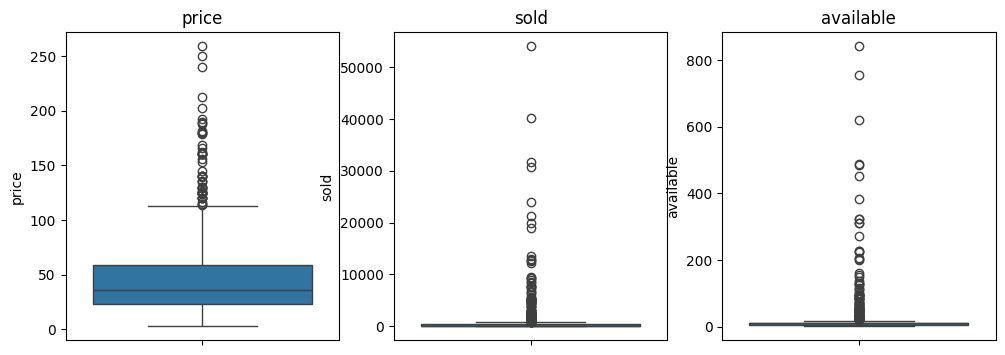


Skewness before log:
 price        2.051648
available    8.650098
sold         9.752849
dtype: float64


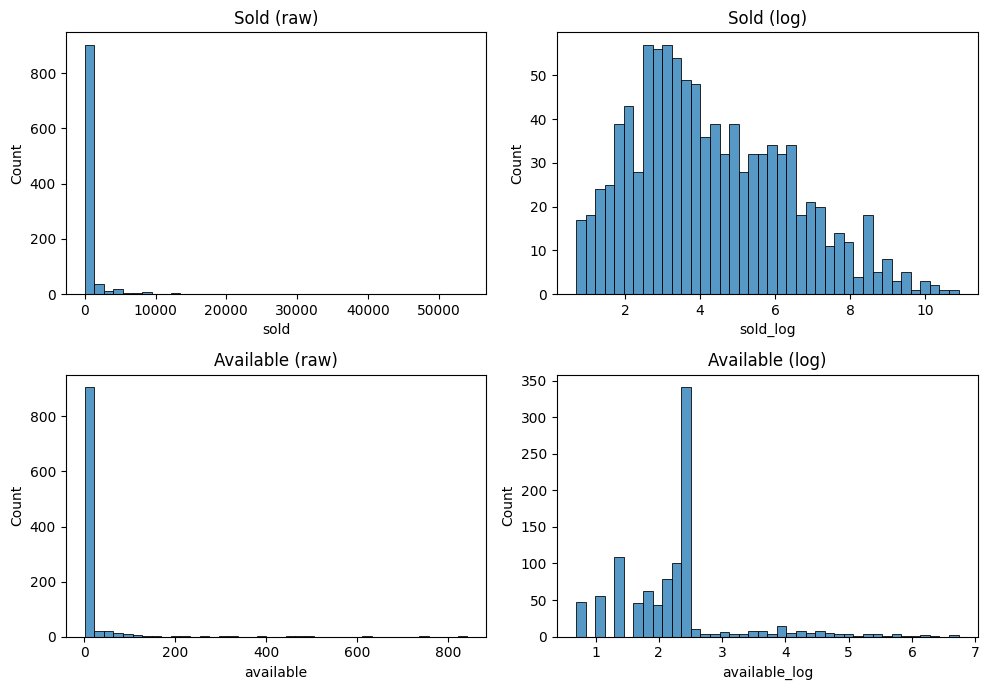

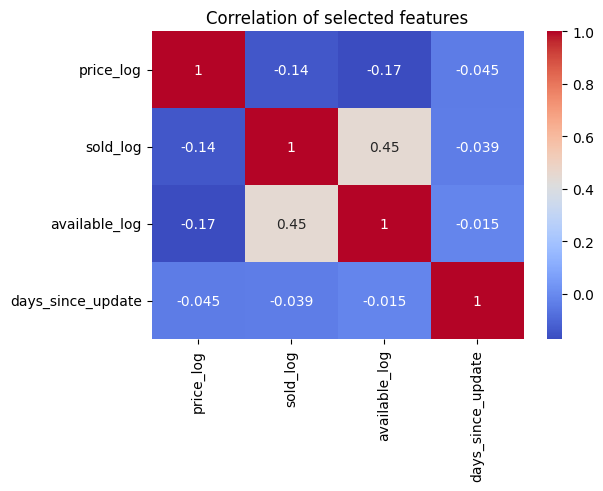


Final data shape: (1000, 13)
Missing values left: 0
   price_log  sold_log  available_log  days_since_update  \
0   4.454231  4.762174       2.397895                0.0   
1   3.603049  3.891820       2.197225                0.0   
2   4.615121  3.332205       2.397895                1.0   
3   3.603049  5.075174       1.098612                0.0   
4   2.885359  5.056246       2.302585                0.0   

   Category_eau de cologne  Category_eau de parfum  Category_eau de toilette  \
0                        0                       1                         0   
1                        0                       1                         0   
2                        0                       0                         1   
3                        0                       0                         1   
4                        0                       0                         0   

   Category_fragrances  Category_other  Category_perfume  Country_Hong Kong  \
0                    0    

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Loading the data
df = pd.read_csv("Sales-[5444].csv")

# 2. BAsic look at the data
print("Shape:", df.shape)
print(df.head())
print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print(df.describe())

# Outlier checking (IQR rule) before the log transform
for col in ["price", "sold", "available"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n} outliers ({n / len(df):.1%})")

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, col in zip(ax, ["price", "sold", "available"]):
    sns.boxplot(y=df[col], ax=a)
    a.set_title(col)
plt.show()


# 3. Extracting 'sold' and 'available' from the 'text' column
#    (the 'sold' column has gaps, but 'text' often contains the number)
sold_from_text = (df["text"].str.extract(r"([\d,]+) sold")[0]
                  .str.replace(",", "").astype(float))
df["sold"] = df["sold"].fillna(sold_from_text)

avail_from_text = (df["text"].str.extract(r"^([\d,]+) available")[0]
                   .str.replace(",", "").astype(float))
df["available"] = df["available"].fillna(avail_from_text)
df.loc[df["text"].str.startswith("Last One", na=False), "available"] = 1

# 4. Cleaning the category column (fix spelling)
df["Category"] = df["Catatory"].str.lower().str.strip()
df["Category"] = df["Category"].replace({"eau de perfume": "eau de parfum"})
top_cats = df["Category"].value_counts().head(5).index
df["Category"] = df["Category"].where(df["Category"].isin(top_cats), "other")
df["Category"] = df["Category"].fillna("other")

# 5. Item location - country, keeping top 2, grouping the rest
df["Country"] = df["itemLocation"].str.split(",").str[-1].str.strip()
df["Country"] = df["Country"].where(df["Country"].isin(["United States", "Hong Kong"]), "Other")

# 6. lastUpdated - number of days since the update
df["lastUpdated"] = pd.to_datetime(df["lastUpdated"].str.replace(r" P[SD]T", "", regex=True),
                                   format="%b %d, %Y %H:%M:%S", errors="coerce")
df["days_since_update"] = (df["lastUpdated"].max() - df["lastUpdated"]).dt.days

# 7. Handling remaining missing values (using median as its safe for skewed data)
for col in ["price", "available", "sold", "days_since_update"]:
    df[col] = df[col].fillna(df[col].median())

# 8. Checking skewness and applying log transform to reduce it
print("\nSkewness before log:\n", df[["price", "available", "sold"]].skew())
df["sold_log"] = np.log1p(df["sold"])
df["available_log"] = np.log1p(df["available"])
df["price_log"] = np.log1p(df["price"])

# 9. Visualising distributions before and after log
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
sns.histplot(df["sold"], bins=40, ax=ax[0, 0]);          ax[0, 0].set_title("Sold (raw)")
sns.histplot(df["sold_log"], bins=40, ax=ax[0, 1]);      ax[0, 1].set_title("Sold (log)")
sns.histplot(df["available"], bins=40, ax=ax[1, 0]);     ax[1, 0].set_title("Available (raw)")
sns.histplot(df["available_log"], bins=40, ax=ax[1, 1]); ax[1, 1].set_title("Available (log)")
plt.tight_layout(); plt.show()

# 10. Selecting the Feature
num_features = ["price_log", "sold_log", "available_log", "days_since_update"]
cat_features = ["Category", "Country"]
df_encoded = pd.get_dummies(df[cat_features]).astype(int)   # one-hot encoding
data = pd.concat([df[num_features], df_encoded], axis=1)

# 11. Correlation heatmap of numeric features
plt.figure(figsize=(6, 4))
sns.heatmap(df[num_features].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation of selected features"); plt.show()

# 12. Final check
print("\nFinal data shape:", data.shape)
print("Missing values left:", data.isnull().sum().sum())
print(data.head())
data.to_csv("clean_data.csv", index=False)

Scaled data shape: (1000, 13)


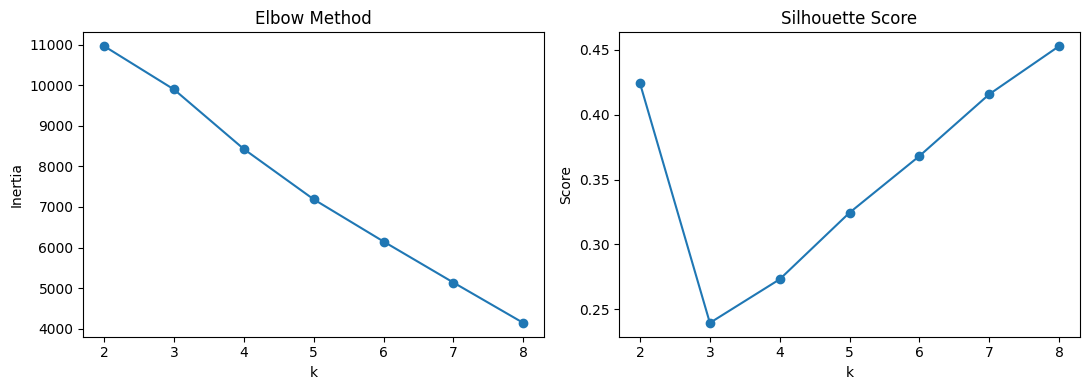

Best k: 8


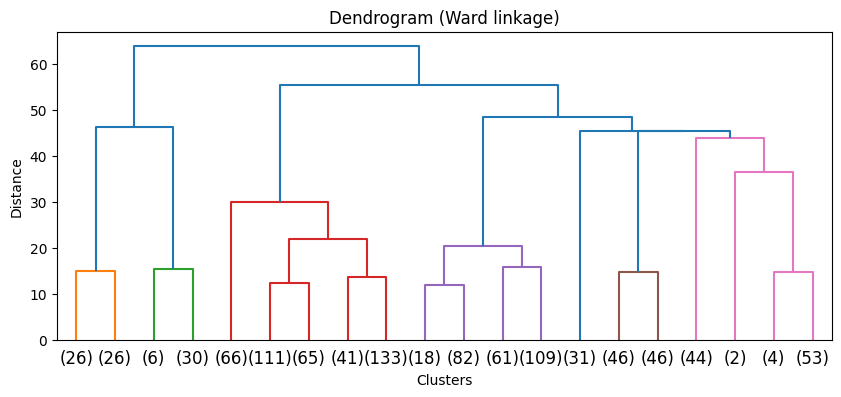

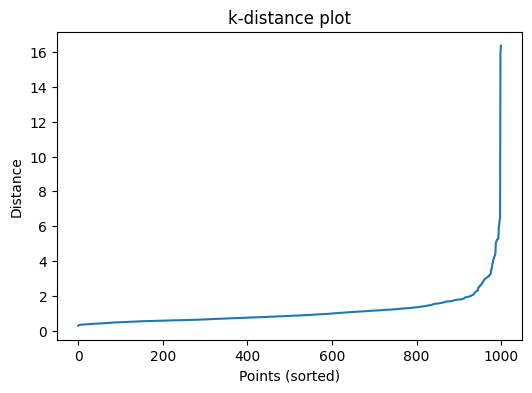

eps=1.5: clusters=9, noise=73, silhouette=0.472
eps=2.0: clusters=9, noise=43, silhouette=0.476
eps=2.5: clusters=9, noise=31, silhouette=0.470
eps=3.0: clusters=7, noise=19, silhouette=0.431
eps=3.5: clusters=7, noise=17, silhouette=0.430
Chosen eps: 2.0

KMeans cluster sizes:
 KMeans
0    270
1    419
2     52
3     31
4     44
5     92
6     36
7     56
Name: count, dtype: int64

Hierarchical cluster sizes:
 Hierarchical
0     59
1    270
2    416
3     36
4     52
5     31
6     92
7     44
Name: count, dtype: int64

DBSCAN cluster sizes:
 DBSCAN
-1     43
 0    269
 1     15
 2    415
 3     31
 4     42
 5     24
 6     89
 7     47
 8     25
Name: count, dtype: int64

           Model  Clusters  Noise points  Silhouette  Davies-Bouldin  \
0        KMeans         8             0       0.453           0.769   
1  Hierarchical         8             0       0.452           0.802   
2        DBSCAN         9            43       0.476           0.678   

   Calinski-Harabasz  
0      

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram

# 1. Loading the cleaned data from Step 1
data = pd.read_csv("clean_data.csv")

# 2. Standard scaling (mean = 0, std = 1)
scaler = StandardScaler()
X = scaler.fit_transform(data)
print("Scaled data shape:", X.shape)

# K-MEANS
# 3. Elbow method and silhouette score to choose k -
inertia, sil = [], []
k_range = range(2, 9)
# Taking max 8 clusters because it keeps results easier to interpret
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_range, inertia, "o-"); ax[0].set_title("Elbow Method")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(k_range, sil, "o-"); ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("k"); ax[1].set_ylabel("Score")
plt.tight_layout(); plt.show()

# 4. Incorporating final K-Means (most suitable k from silhouette)
best_k = list(k_range)[int(np.argmax(sil))]
print("Best k:", best_k)
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
data["KMeans"] = kmeans.fit_predict(X)

# Hierarchical
# 5. Dendrogram (Ward linkage)
plt.figure(figsize=(10, 4))
dendrogram(linkage(X, method="ward"), truncate_mode="lastp", p=20)
plt.title("Dendrogram (Ward linkage)"); plt.xlabel("Clusters"); plt.ylabel("Distance")
plt.show()

# 6. Fitting Agglomerative Clustering with the same k
hier = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
data["Hierarchical"] = hier.fit_predict(X)

# DBSCAN
# 7. k-distance plot to help choose eps (min_samples = number of features)
min_samples = X.shape[1]
dist, _ = NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)
plt.figure(figsize=(6, 4))
plt.plot(np.sort(dist[:, -1]))
plt.title("k-distance plot"); plt.xlabel("Points (sorted)"); plt.ylabel("Distance")
plt.show()

# 8. Trying a few eps values and keeping the best silhouette with less than 10% noise
best_eps, best_s = None, -1
for eps in [1.5, 2.0, 2.5, 3.0, 3.5]:
    lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    noise = (lab == -1).sum()
    if n_cl >= 2:
        s = silhouette_score(X[lab != -1], lab[lab != -1])
        print(f"eps={eps}: clusters={n_cl}, noise={noise}, silhouette={s:.3f}")
        if s > best_s and noise < 0.10 * len(X):
            best_eps, best_s = eps, s
print("Chosen eps:", best_eps)
data["DBSCAN"] = DBSCAN(eps=best_eps, min_samples=min_samples).fit_predict(X)

# 9. Cluster sizes for each method
for m in ["KMeans", "Hierarchical", "DBSCAN"]:
    print(f"\n{m} cluster sizes:\n", data[m].value_counts().sort_index())

# 10. Comparing the three models with validation metrics, also for DBSCAN, I have left the noise points out of the score for better result and not distorted
rows = []
for m in ["KMeans", "Hierarchical", "DBSCAN"]:
    mask = data[m] != -1
    rows.append({"Model": m,
                 "Clusters": data.loc[mask, m].nunique(),
                 "Noise points": (~mask).sum(),
                 "Silhouette": silhouette_score(X[mask], data.loc[mask, m]),
                 "Davies-Bouldin": davies_bouldin_score(X[mask], data.loc[mask, m]),
                 "Calinski-Harabasz": calinski_harabasz_score(X[mask], data.loc[mask, m])})
results = pd.DataFrame(rows).round(3)
print("\n", results)

np.save("X_scaled.npy", X)
data.to_csv("clustered_data.csv", index=False)

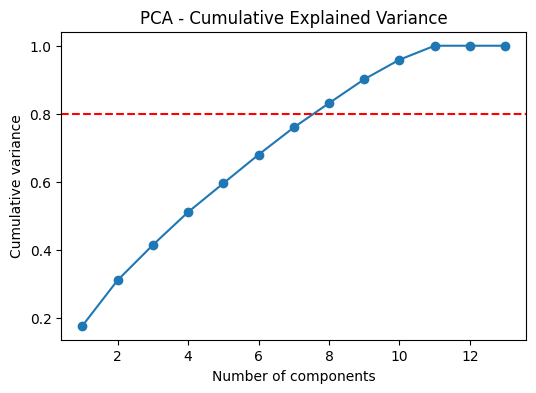

Components needed for 80% variance: 8
Variance explained by PC1 + PC2: 0.312


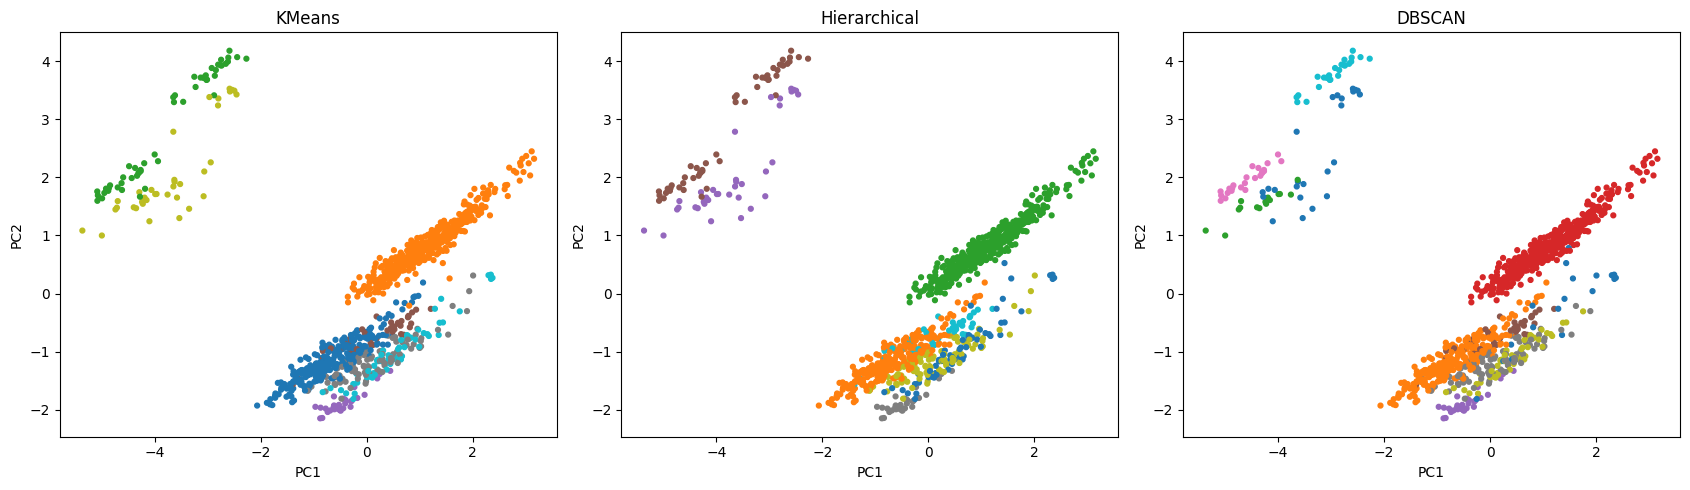

         products  avg_price  median_sold  total_sold  avg_available  \
Cluster                                                                
0             270       57.4         39.0     67551.0           11.4   
1             419       39.6        157.0    558265.0           28.8   
2              52       62.3         18.5      1804.0            6.3   
3              31       32.4         12.0       927.0            3.5   
4              44       41.4         48.5      6002.0            8.5   
5              92       47.0         34.5    102447.0            9.8   
6              36       57.0         24.0      1672.0            7.6   
7              56       32.8        108.0     30949.0           23.6   

         avg_days_old     top_category    top_country  
Cluster                                                
0                 6.3    eau de parfum  United States  
1                 8.5  eau de toilette  United States  
2                 5.1  eau de toilette      Hong Kong  

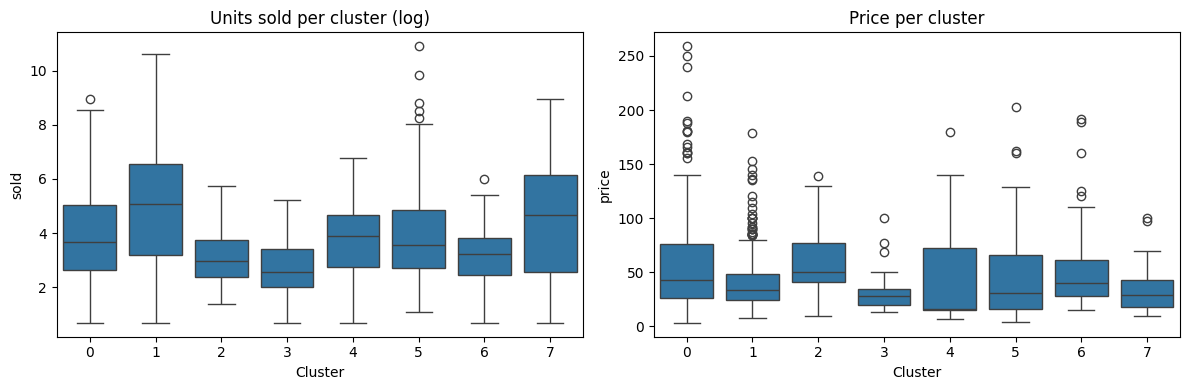

Category  eau de cologne  eau de parfum  eau de toilette  fragrances  other  \
Cluster                                                                       
0                      0            270                0           0      0   
1                      0              0              419           0      0   
2                      1             24               26           0      1   
3                      0              0                0          31      0   
4                      0              0                0           0      0   
5                      0              0                0           0     92   
6                      0             16                9           1      4   
7                     56              0                0           0      0   

Category  perfume  
Cluster            
0               0  
1               0  
2               0  
3               0  
4              44  
5               0  
6               6  
7               0  
Country  

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Loading scaled data and clustering results from Step 2
X = np.load("X_scaled.npy")
data = pd.read_csv("clustered_data.csv")

# PCA
# 2. Checking that how much variance does each component explain?
pca_full = PCA().fit(X)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, "o-")
plt.axhline(0.80, color="red", linestyle="--")
plt.title("PCA - Cumulative Explained Variance")
plt.xlabel("Number of components"); plt.ylabel("Cumulative variance")
plt.show()
print("Components needed for 80% variance:", np.argmax(cum_var >= 0.80) + 1)

# 3. Reducing to 2 components for visualisation
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
print("Variance explained by PC1 + PC2:", pca.explained_variance_ratio_.sum().round(3))

# 4. Plotting the clusters from all three models
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, m in zip(ax, ["KMeans", "Hierarchical", "DBSCAN"]):
    a.scatter(X_pca[:, 0], X_pca[:, 1], c=data[m], cmap="tab10", s=12)
    a.set_title(m); a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

# MOdel Selection
# 5. Final model is K-Means (justified in the report)
final = "KMeans"

# CLuster Profiling
# 6. Converting log features back to real values as they are easier to read
profile = pd.DataFrame({
    "price": np.expm1(data["price_log"]),
    "sold": np.expm1(data["sold_log"]),
    "available": np.expm1(data["available_log"]),
    "days_since_update": data["days_since_update"],
    "Cluster": data[final]})

# 7. Recovering category and country from the one-hot columns
cat_cols = [c for c in data.columns if c.startswith("Category_")]
cty_cols = [c for c in data.columns if c.startswith("Country_")]
profile["Category"] = data[cat_cols].idxmax(axis=1).str.replace("Category_", "")
profile["Country"] = data[cty_cols].idxmax(axis=1).str.replace("Country_", "")

# 8. Average numeric values per cluster
summary = profile.groupby("Cluster").agg(
    products=("price", "size"),
    avg_price=("price", "mean"),
    median_sold=("sold", "median"),
    total_sold=("sold", "sum"),
    avg_available=("available", "mean"),
    avg_days_old=("days_since_update", "mean"),
    top_category=("Category", lambda s: s.mode()[0]),
    top_country=("Country", lambda s: s.mode()[0])).round(1)
print(summary)

# 9. Plots used sales and price per cluster
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x="Cluster", y=np.log1p(profile["sold"]), data=profile, ax=ax[0])
ax[0].set_title("Units sold per cluster (log)")
sns.boxplot(x="Cluster", y="price", data=profile, ax=ax[1])
ax[1].set_title("Price per cluster")
plt.tight_layout(); plt.show()

# 10. Category and country mix per cluster
print(pd.crosstab(profile["Cluster"], profile["Category"]))
print(pd.crosstab(profile["Cluster"], profile["Country"]))

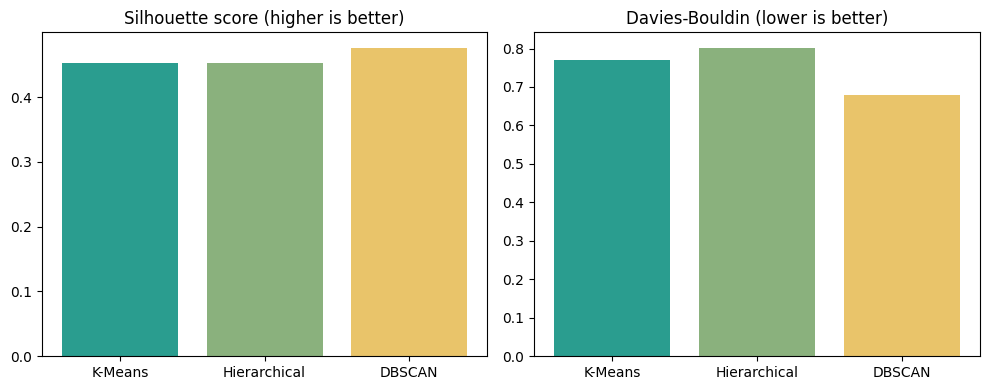

Silhouette (numeric measures only): 0.273
Adjusted Rand index: 0.993
Products in matching groups: 99.7%


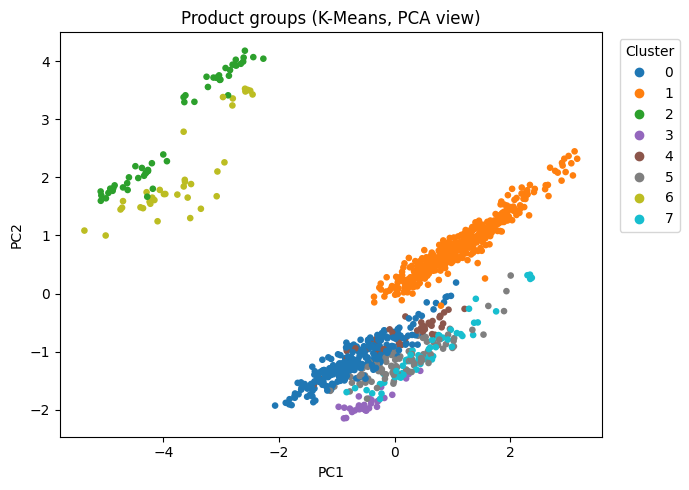

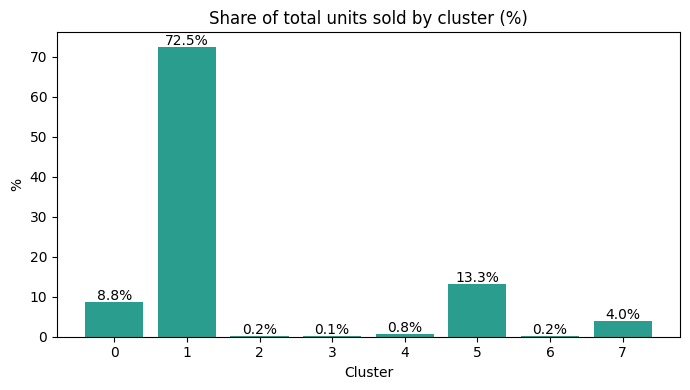

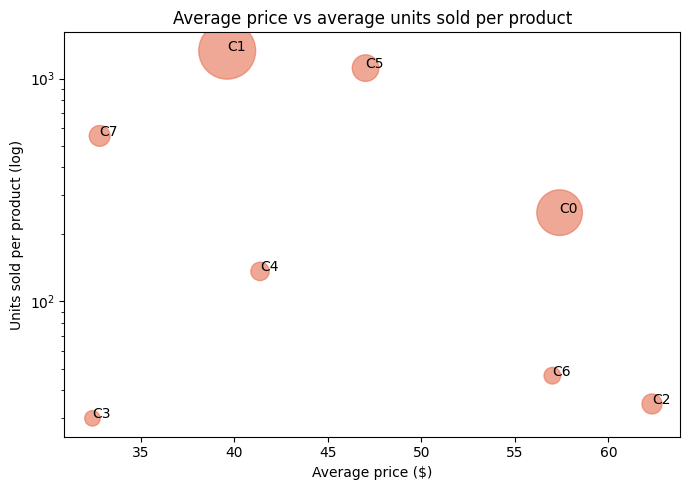

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

X = np.load("X_scaled.npy")
data = pd.read_csv("clustered_data.csv")

# Real-value table per cluster (from Step 3)
p = pd.DataFrame({"Cluster": data["KMeans"],
                  "price": np.expm1(data["price_log"]),
                  "sold": np.expm1(data["sold_log"])})
s = p.groupby("Cluster").agg(products=("price", "size"), price=("price", "mean"),
                             total_sold=("sold", "sum"))

# Chart 1: Model comparison (uding the scores from Step 2)
models = ["K-Means", "Hierarchical", "DBSCAN"]
sil = [0.453, 0.452, 0.476]
db = [0.769, 0.802, 0.678]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(models, sil, color=["#2a9d8f", "#8ab17d", "#e9c46a"])
ax[0].set_title("Silhouette score (higher is better)")
ax[1].bar(models, db, color=["#2a9d8f", "#8ab17d", "#e9c46a"])
ax[1].set_title("Davies-Bouldin (lower is better)")
plt.tight_layout(); plt.show()

# Checking if groups using the numeric measures only
num_cols = ["price_log", "sold_log", "available_log", "days_since_update"]
X_num = StandardScaler().fit_transform(data[num_cols])
km_num = KMeans(n_clusters=8, random_state=42, n_init=10).fit(X_num)
print("Silhouette (numeric measures only):", round(silhouette_score(X_num, km_num.labels_), 3))

# Checking how closely K-Means and Hierarchical agree
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment
ct = pd.crosstab(data["KMeans"], data["Hierarchical"]).values
r, c = linear_sum_assignment(-ct)
print("Adjusted Rand index:", round(adjusted_rand_score(data["KMeans"], data["Hierarchical"]), 3))
print("Products in matching groups:", f"{ct[r, c].sum() / ct.sum():.1%}")

# Chart 2: Product groups on a 2D map (PCA)
X_pca = PCA(n_components=2, random_state=42).fit_transform(X)
plt.figure(figsize=(7, 5))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=data["KMeans"], cmap="tab10", s=14)
plt.legend(*sc.legend_elements(), title="Cluster", bbox_to_anchor=(1.02, 1))
plt.title("Product groups (K-Means, PCA view)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.tight_layout(); plt.show()

# Chart 3: Share of total units sold per cluster
share = (s["total_sold"] / s["total_sold"].sum() * 100).round(1)
plt.figure(figsize=(7, 4))
plt.bar(share.index.astype(str), share.values, color="#2a9d8f")
plt.title("Share of total units sold by cluster (%)")
plt.xlabel("Cluster"); plt.ylabel("%")
for i, v in enumerate(share.values):
    plt.text(i, v + 0.5, f"{v}%", ha="center")
plt.tight_layout(); plt.show()

# Chart 4: price vs sales (bubble size is number of products)
plt.figure(figsize=(7, 5))
plt.scatter(s["price"], s["total_sold"] / s["products"], s=s["products"] * 4,
            alpha=0.6, color="#e76f51")
for c in s.index:
    plt.annotate(f"C{c}", (s.loc[c, "price"], s.loc[c, "total_sold"] / s.loc[c, "products"]))
plt.yscale("log")
plt.title("Average price vs average units sold per product")
plt.xlabel("Average price ($)"); plt.ylabel("Units sold per product (log)")
plt.tight_layout(); plt.show()